# ДЗ 1. Рекомендации книг

Русскин Филипп Сергеевич

## 1. Данные

Использую [Goodreads Poetry / UCSD Book Graph](https://mengtingwan.github.io/data/goodreads.html).
Это взаимодействия пользователей с книгами из раздела поэзии. Исходные файлы взяты
[с сервера авторов](https://mcauleylab.ucsd.edu/public_datasets/gdrive/goodreads/byGenre/).
В них 2 734 350 взаимодействий и 36 514 записей об изданиях (информация о книге).

Хотим рекомендовать 10 новых для пользователя произведений. Релевантной считаю книгу с оценкой 4 или 5.
Разные издания объединяю по `work_id`, чтобы не рекомендовать переиздание уже известной книги.

| Поле | Значение |
|---|---|
| user_id, book_id | Пользователь и издание |
| work_id | Произведение |
| rating | Оценка от 1 до 5; 0 — оценки нет |
| is_read | Прочитана ли книга |
| date_added, date_updated | Добавление записи и последнее обновление |
| title, authors, language_code, publication_year, num_pages | Название, автор, язык, год и число страниц |

Запуск: нужен python 3.12, затем открыть ноутбук через
`jupyter lab` и выполнить все ячейки. Два файла суммарным размером 170 мб скачаются в `data/raw/`: в одном лежит информация о книгах: ID издания и произведения, название, язык и тд, во втором взаимодействия: ID пользователя и книги, оценка, отметка «прочитано» и тд.
Эти данные в гитигноре и на гитхаб не загружаются. Все 5 моделей лежат в `models/`.

In [15]:
from pathlib import Path
from urllib.request import urlretrieve
import gzip
import hashlib
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.sparse import csr_matrix
from models.item_knn import ItemKNN
from models.ials import ALS
from models.ease import EASE
from models.fm import FM
from models.custom_als import CustomALS

%matplotlib inline
SEED = 42
K = 10
TRAIN_END = pd.Timestamp('2015-01-01', tz='UTC')
VALID_END = pd.Timestamp('2016-01-01', tz='UTC')
np.random.seed(SEED)
pd.set_option('display.max_colwidth', 100)

Проверим количество книг, пользователей и взаимодействий:

In [16]:
folder = Path('data/raw')
folder.mkdir(parents=True, exist_ok=True)
url = 'https://mcauleylab.ucsd.edu/public_datasets/gdrive/goodreads/byGenre/'
names = ['goodreads_books_poetry.json.gz', 'goodreads_interactions_poetry.json.gz']

for name in names:
    if not (folder / name).exists():
        urlretrieve(url + name, folder / name)

def read_json(name, columns):
    rows = []
    with gzip.open(folder / name, 'rt', encoding='utf-8') as f:
        for line in f:
            row = json.loads(line)
            rows.append([row.get(column) for column in columns])
    return pd.DataFrame(rows, columns=columns)


books = read_json(names[0], ['book_id', 'work_id', 'title', 'authors', 'language_code',
                            'publication_year', 'num_pages'])
events = read_json(names[1], ['user_id', 'book_id', 'rating', 'is_read',
                             'date_added', 'date_updated'])

raw_size = len(events)
print('Исходник:', raw_size, 'взаимодействий,',
      events.user_id.nunique(), 'пользователей,', len(books), 'изданий')

Исходник: 2734350 взаимодействий, 377799 пользователей, 36514 изданий


## 2. Подготовка и EDA

Удалим строки с неверными датами, оценками и отсутствующими метаданными. Время взаимодействия —
максимум `date_added` и `date_updated`: в строке хранится последнее состояние, поэтому оценку
нельзя автоматически относить к дате добавления книги. Повторные user–work это повторная запись пользователя о книге (но возможно другой версии издания).

По данным до 2015 года выбираю 3000 произведений с наибольшим числом оценок 4–5.
Это ограничивает размер плотной матрицы EASE. Оставляю пользователей с минимум тремя
взаимодействиями и хотя бы одной положительной оценкой в этом каталоге. Из них беру 20 000
по порядку SHA256("42:user_id") (чтобы выборка была воспроизводимой). Посчитаем сколько между этими пользователями и книгами будет взаимодействий:

In [17]:
quality = {'Дубликаты user–book': int(events.duplicated(['user_id', 'book_id']).sum())}
books = books.drop_duplicates('book_id').copy()
missing_work = books.work_id.isna() | books.work_id.isin(['', '0'])
books['work_id'] = np.where(missing_work, 'book:' + books.book_id, 'work:' + books.work_id)
fmt = '%a %b %d %H:%M:%S %z %Y'
added = pd.to_datetime(events.date_added, format=fmt, errors='coerce', utc=True)
updated = pd.to_datetime(events.date_updated, format=fmt, errors='coerce', utc=True)
events['timestamp'] = updated.where(updated >= added, added)
events['rating'] = pd.to_numeric(events.rating, errors='coerce')
ok = (added.notna() & updated.notna() & events.user_id.notna() & events.rating.between(0, 5)
      & events.timestamp.ge(pd.Timestamp('2006-01-01', tz='UTC'))
      & events.timestamp.lt(pd.Timestamp('2018-01-01', tz='UTC')))
quality['Некорректные строки'] = int((~ok).sum())
events = events.loc[ok, ['user_id', 'book_id', 'rating', 'is_read', 'timestamp']].copy()
events['is_read'] = events.is_read.fillna(False).astype(bool)
before = len(events)
events = events.merge(books[['book_id', 'work_id']], on='book_id')
quality['Без метаданных'] = before - len(events)
events = events.sort_values(['timestamp', 'book_id'], kind='stable')
before = len(events)
events = events.drop_duplicates(['user_id', 'work_id'])
quality['Повторные user–work'] = before - len(events)
clean_size = len(events)
display(pd.Series(quality, name='Количество').to_frame())

,Количество
Дубликаты user–book,0
Некорректные строки,0
Без метаданных,0
Повторные user–work,16868


In [18]:
history = events[events.timestamp < TRAIN_END]
popular = (history[history.rating >= 4].groupby('work_id').size().rename('count').reset_index()
           .sort_values(['count', 'work_id'], ascending=[False, True]))
works = popular.head(3000).work_id
history = history[history.work_id.isin(works)]
counts = history.groupby('user_id').size()
liked = set(history.loc[history.rating >= 4, 'user_id'])
users = [u for u in counts[counts >= 3].index if u in liked]
users = sorted(users, key=lambda u: hashlib.sha256(f'{SEED}:{u}'.encode()).digest())[:20000]
events = events[events.user_id.isin(users) & events.work_id.isin(works)].copy()
works = sorted(events.loc[events.timestamp < TRAIN_END, 'work_id'].unique())
events = events[events.work_id.isin(works)].copy()
user_ids = {u: i for i, u in enumerate(sorted(users))}
item_ids = {w: i for i, w in enumerate(works)}
events['u'] = events.user_id.map(user_ids)
events['i'] = events.work_id.map(item_ids)
shape = (len(user_ids), len(item_ids))
history = events[events.timestamp < TRAIN_END]
first_editions = history.drop_duplicates('work_id')[['work_id', 'book_id']]
items = first_editions.merge(books, on=['work_id', 'book_id'])
items['i'] = items.work_id.map(item_ids)
items = items.sort_values('i').reset_index(drop=True)

assert 100000 <= len(events) <= 2000000 and min(shape) >= 1000
assert not events.duplicated(['u', 'i']).any()
display(pd.DataFrame({'Этап': ['Исходник', 'После очистки', 'После отбора'],
                      'Взаимодействия': [raw_size, clean_size, len(events)]}))
print('Итог:', shape[0], 'пользователей,', shape[1], 'произведений')
print('Оценок 4–5:', int((events.rating >= 4).sum()))
print(f'Разреженность: {1 - len(events) / (shape[0] * shape[1]):.3%}')

,Этап,Взаимодействия
0,Исходник,2734350
1,После очистки,2717482
2,После отбора,263339


Итог: 20000 пользователей, 3000 произведений
Оценок 4–5: 118071
Разреженность: 99.561%


Посмотрим на наши данные в train и построим графички:

,Пропуски в метаданных
author,0
language,1294
publication_year,346
num_pages,332


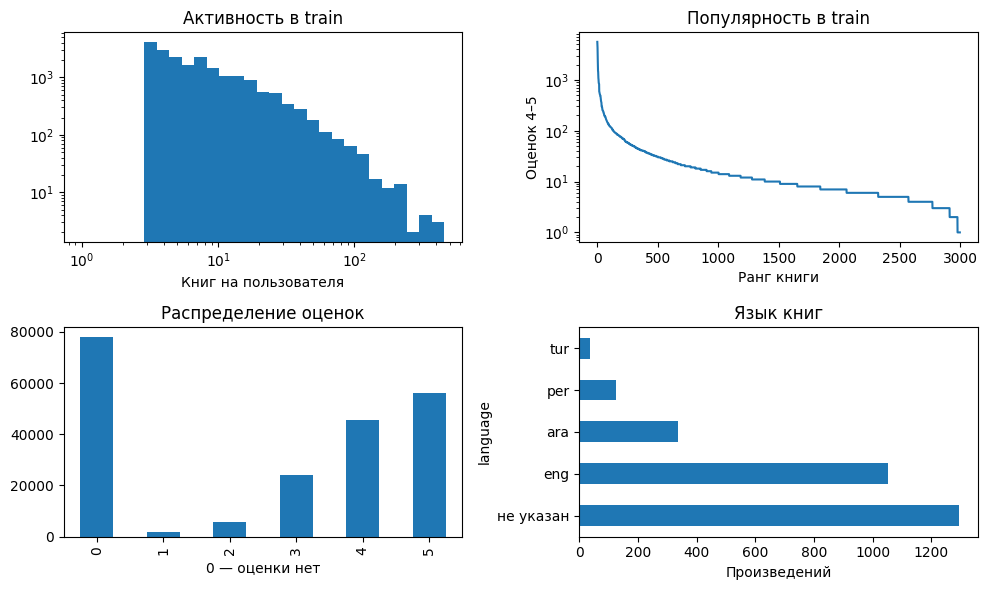

In [19]:
items['author'] = items.authors.map(lambda a: str(a[0]['author_id']) if a else '')
items['language'] = items.language_code.fillna('').replace({'en-US': 'eng', 'en-GB': 'eng', 'en-CA': 'eng'})
for column in ['publication_year', 'num_pages']:
    items[column] = pd.to_numeric(items[column], errors='coerce')
    items.loc[items[column] <= 0, column] = np.nan
items.loc[items.publication_year > TRAIN_END.year, 'publication_year'] = np.nan
metadata = items[['author', 'language', 'publication_year', 'num_pages']]
display((metadata.isna() | metadata.eq('')).sum().rename('Пропуски в метаданных').to_frame())

fig, axes = plt.subplots(2, 2, figsize=(10, 6))
activity = history.groupby('u').size()
axes[0, 0].hist(activity, bins=np.geomspace(1, activity.max() + 1, 30))
axes[0, 0].set(xscale='log', yscale='log', title='Активность в train', xlabel='Книг на пользователя')
popularity = history[history.rating >= 4].groupby('i').size().sort_values(ascending=False)
axes[0, 1].plot(np.arange(1, len(popularity) + 1), popularity.values)
axes[0, 1].set(yscale='log', title='Популярность в train', xlabel='Ранг книги', ylabel='Оценок 4–5')
history.rating.value_counts().sort_index().plot.bar(ax=axes[1, 0])
axes[1, 0].set(title='Распределение оценок', xlabel='0 — оценки нет')
items.language.replace('', 'не указан').value_counts().head(5).plot.barh(ax=axes[1, 1])
axes[1, 1].set(title='Язык книг', xlabel='Произведений')
plt.tight_layout()
plt.show()

Большинство пользователей взаимодействовало с небольшим числом книг, обычно меньше 100. Аналогично популярных книг единицы <100, а у большинства оценок 4-5 меньше 10. Отбор отсеивает часть данных и результаты относятся к активным
пользователям и самой популярной части каталога.


## 3. Протокол

Делим данные на три части. Train — до 01.01.2015, validation — 2015 год, test — 2016–2017 годы.
Настройки выбираю по NDCG@10 на validation. После выбора переобучаю на train + validation.
На test у всех моделей критерий релевантности это оценка не ниже 4.

Кандидаты это весь выбранный каталог, кроме всех уже известных пользователю произведений,
включая книги без оценки. Новые пользователи и книги вне train-каталога исключены.
В каждом отложенном периоде оцениваю пользователей с хотя бы одной релевантной книгой.
Этот набор одинаков для всех моделей; негативы при оценке не сэмплирую.

NDCG учитывает порядок рекомендаций, Recall же просто долю найденных релевантных книг.
Считается как среднее по пользователям:

$$Recall@10_u=\frac{|R_u^{10}\cap T_u|}{|T_u|},\qquad
NDCG@10_u=\frac{\sum_{j=1}^{10}\mathbb{1}[R_{uj}\in T_u]/\log_2(j+1)}
{\sum_{j=1}^{\min(10,|T_u|)}1/\log_2(j+1)}.$$

In [ ]:
train = events[events.timestamp < TRAIN_END].sort_values(['u', 'i']).reset_index(drop=True)
valid = events[(events.timestamp >= TRAIN_END) & (events.timestamp < VALID_END)]
valid = valid.sort_values(['u', 'i']).reset_index(drop=True)
test = events[events.timestamp >= VALID_END].sort_values(['u', 'i']).reset_index(drop=True)

split_stats = []
for name, part in [('train', train), ('validation', valid), ('test', test)]:
    positive = part[part.rating >= 4]
    split_stats.append({
        'Часть': name,
        'Взаимодействия': len(part),
        'Пользователи': part.u.nunique(),
        'Книги': part.i.nunique(),
        'Оценки 4–5': len(positive),
        'Пользователи для оценки': positive.u.nunique()
    })
display(pd.DataFrame(split_stats))
assert train.timestamp.max() < valid.timestamp.min()
assert valid.timestamp.max() < test.timestamp.min()

decade = items.publication_year // 10 * 10
decade = decade.fillna(-1).astype(int).astype(str)
pages = pd.cut(items.num_pages, [0, 50, 100, 200, 400, 800, 2000, np.inf], labels=False)
pages = pages.fillna(-1).astype(int).astype(str)

columns = [np.arange(shape[1]) + shape[0]]
offset = sum(shape)
for values in [items.author, items.language, decade, pages]:
    codes, categories = pd.factorize(values.replace('', '<unknown>'), sort=True)
    columns.append(codes + offset)
    offset += len(categories)
features = np.column_stack(columns)

def matrix(frame):
    rows = frame.u.to_numpy()
    cols = frame.i.to_numpy()
    values = np.ones(len(frame))
    return csr_matrix((values, (rows, cols)), shape=shape)

def training_data(frame, cutoff):
    positive = frame[frame.rating >= 4]
    return {
        'events': frame,
        'positive': matrix(positive),
        'seen': matrix(frame),
        'features': features,
        'cutoff': cutoff
    }

def recommend(model, user, seen, k=K):
    scores = model.score([user])[0]
    scores[seen[user].indices] = -np.inf
    return np.argsort(-scores, kind='stable')[:k]

def evaluate(model, data, heldout):
    positive = heldout[heldout.rating >= 4]
    ground_truth = positive.groupby('u')['i'].apply(set).to_dict()
    ndcg_values = []
    recall_values = []

    for user, relevant in ground_truth.items():
        recs = recommend(model, user, data['seen'])
        hits = len(set(recs) & relevant)
        recall_values.append(hits / len(relevant))

        dcg = 0
        for rank, item in enumerate(recs):
            if item in relevant:
                dcg += 1 / np.log2(rank + 2)

        idcg = 0
        for rank in range(min(K, len(relevant))):
            idcg += 1 / np.log2(rank + 2)
        ndcg_values.append(dcg / idcg)

    return {'NDCG@10': np.mean(ndcg_values), 'Recall@10': np.mean(recall_values)}

,Часть,Взаимодействия,Пользователи,Книги,Оценки 4–5,Пользователи для оценки
0,train,211317,20000,3000,101890,20000
1,validation,22799,5774,2653,7105,3044
2,test,29223,6443,2740,9076,3407


## 4. Модели

**ItemKNN.** Ставлю $X_{ui}=1$ для оценок 4–5, иначе 0.
Сходство книг — косинус с поправкой на число общих пользователей:

$$
s_{ij}=\frac{X_i^TX_j}{\|X_i\|\|X_j\|}
\cdot\frac{n_{ij}}{n_{ij}+25}.
$$

Поправка снижает доверие к редким совпадениям. Оставляю ближайших
соседей каждой книги. Балл рекомендации — сумма сходств с книгами,
понравившимися пользователю.

**iALS.** Подбираю векторы пользователей и книг, чтобы их скалярное
произведение приближалось к таргету: 1 для оценок 4–5, иначе 0.

$$
L=\sum_{u,i}c_{ui}(p_{ui}-a_u^Tb_i)^2
+\lambda(\|A\|_F^2+\|B\|_F^2).
$$

Для известных пар $c_{ui}=1+\alpha$, для остальных — 1.
По очереди обновляю векторы пользователей и книг через решение
линейных систем. Предсказание — $a_u^Tb_i$.
Известные книги без оценки тоже имеют повышенный вес и нулевой
таргет — это упрощение модели.

**EASE.** Обучаю связи между книгами, восстанавливая предпочтения
пользователя по его истории:

$$
\min_W\|X-XW\|_F^2+\lambda\|W\|_F^2,\qquad W_{ii}=0.
$$

Нулевая диагональ запрещает книге предсказывать саму себя.
Веса нахожу аналитически, баллы рекомендаций получаю из $XW$.

**FM.** Использую ID пользователя и произведения, автора, язык,
десятилетие публикации и диапазон числа страниц. FM учитывает
отдельные признаки и их сочетания:

$$
f(x)=w_0+\sum_jw_jx_j+\sum_{j<k}(v_j^Tv_k)x_jx_k.
$$

Метаданные беру у первого издания, встретившегося в train.
Они помогают учитывать автора, язык и объём книги. Считаю их
доступными при рекомендации, хотя исторических снимков нет.
Рейтинги и число отзывов из полного датасета не использую.

Обучаю сигмоиду от $f(x)$ по бинарной кросс-энтропии,
ранжирую по самому $f(x)$. Метка 1 — оценки 4–5, иначе 0.
На каждой эпохе добавляю один случайный негатив на положительный
пример, исключая обучающую историю. 

**ALS с новым таргетом.** Учитываю строгость пользователя,
прочтение и давность. Среднюю оценку пользователя $\mu_u$
сглаживаю пятью условными оценками, равными общей средней train.

Для выставленной оценки сигнал равен
$q_{ui}=\operatorname{clip}((r_{ui}-3)/4+(r_{ui}-\mu_u)/4,-1,1)$.
Для прочитанной книги без оценки беру 0.25, для добавленной
на полку без оценки — 0.05. Учитываю давность:

$$
p^*_{ui}=q_{ui}\cdot2^{-\Delta t_{ui}/1095}.
$$

Здесь $\Delta t_{ui}$ — дни до границы обучения. Для неизвестных
пар таргет 0. Веса доверия сохраняю как в базовом ALS.
Средние и давность считаю только по обучающей части.

### Подбор

Для обоих ALS фиксирую 12 итераций и $\alpha=20$.
Для FM — 6 эпох, шаг 0.05, L2 0.0001, batch size 2048
и один негатив на положительный пример. Seed = 42.

Настройки выбираю по максимуму NDCG@10 на validation,
при равенстве — первый вариант.

In [23]:
classes = {'ItemKNN': ItemKNN, 'iALS': ALS, 'EASE': EASE, 'FM': FM, 'CustomALS': CustomALS}
als_grid = [
    {'factors': 32, 'reg': 1},
    {'factors': 32, 'reg': 10},
    {'factors': 64, 'reg': 1},
    {'factors': 64, 'reg': 10}
]
grids = {
    'ItemKNN': [{'neighbors': 50}, {'neighbors': 150}],
    'iALS': als_grid,
    'EASE': [{'reg': 100}, {'reg': 500}],
    'FM': [{'factors': 16}, {'factors': 32}],
    'CustomALS': als_grid
}

train_data = training_data(train, TRAIN_END)
trials = []
best_params = {}
for name, model_class in classes.items():
    best_score = -1
    for params in grids[name]:
        model = model_class(**params).fit(train_data)
        metrics = evaluate(model, train_data, valid)
        trials.append({'Модель': name, 'Параметры': params, **metrics})
        if metrics['NDCG@10'] > best_score:
            best_score = metrics['NDCG@10']
            best_params[name] = params
display(pd.DataFrame(trials))
display(pd.Series(best_params, name='Выбранные параметры').to_frame())

,Модель,Параметры,NDCG@10,Recall@10
0,ItemKNN,{'neighbors': 50},0.150584,0.212418
1,ItemKNN,{'neighbors': 150},0.150808,0.212975
2,iALS,"{'factors': 32, 'reg': 1}",0.090536,0.143934
3,iALS,"{'factors': 32, 'reg': 10}",0.088730,0.140788
4,iALS,"{'factors': 64, 'reg': 1}",0.083463,0.127257
5,iALS,"{'factors': 64, 'reg': 10}",0.082462,0.125399
6,EASE,{'reg': 100},0.157806,0.227733
7,EASE,{'reg': 500},0.154433,0.218630
8,FM,{'factors': 16},0.056346,0.088066
9,FM,{'factors': 32},0.069441,0.103711


,Выбранные параметры
ItemKNN,{'neighbors': 150}
iALS,"{'factors': 32, 'reg': 1}"
EASE,{'reg': 100}
FM,{'factors': 32}
CustomALS,"{'factors': 64, 'reg': 10}"


## 5. Результаты на test

Теперь переобучаю выбранные модели на train + validation. Пользователи, каталог,
фильтрация известных книг и релевантность одинаковы для всех методов.

,Модель,NDCG@10,Recall@10,Параметры
0,EASE,0.152873,0.213860,{'reg': 100}
1,ItemKNN,0.139226,0.190998,{'neighbors': 150}
2,iALS,0.088690,0.134788,"{'factors': 32, 'reg': 1}"
3,CustomALS,0.074125,0.105024,"{'factors': 64, 'reg': 10}"
4,FM,0.071754,0.103056,{'factors': 32}


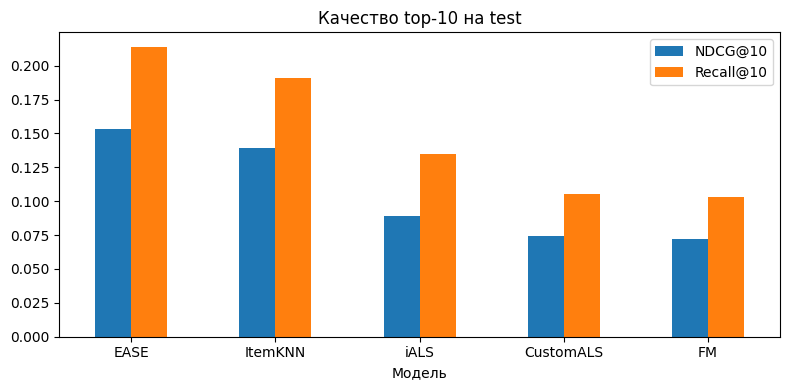

In [24]:
fit_data = training_data(pd.concat([train, valid], ignore_index=True), VALID_END)
fitted, results = {}, []
for name, cls in classes.items():
    fitted[name] = cls(**best_params[name]).fit(fit_data)
    results.append({'Модель': name, **evaluate(fitted[name], fit_data, test),
                    'Параметры': best_params[name]})
results = pd.DataFrame(results).sort_values('NDCG@10', ascending=False).reset_index(drop=True)
display(results)
results.set_index('Модель')[['NDCG@10', 'Recall@10']].plot.bar(figsize=(8, 4), rot=0)
plt.title('Качество top-10 на test')
plt.tight_layout()
plt.show()

In [25]:
fm_ids = FM(**best_params['FM'], metadata=False).fit(fit_data)
custom_matched = CustomALS(**best_params['iALS']).fit(fit_data)
checks = pd.DataFrame([
    {'Вариант': 'FM с метаданными', **evaluate(fitted['FM'], fit_data, test)},
    {'Вариант': 'FM только с ID', **evaluate(fm_ids, fit_data, test)},
    {'Вариант': 'iALS', **evaluate(fitted['iALS'], fit_data, test)},
    {'Вариант': 'Новый таргет, настройки iALS', **evaluate(custom_matched, fit_data, test)}])
display(checks)

,Вариант,NDCG@10,Recall@10
0,FM с метаданными,0.071754,0.103056
1,FM только с ID,0.076946,0.109102
2,iALS,0.088690,0.134788
3,"Новый таргет, настройки iALS",0.068568,0.102557


In [26]:
user = int(test.loc[test.rating >= 4, 'u'].min())
winner = results.iloc[0]['Модель']
top10 = recommend(fitted[winner], user, fit_data['seen'])
print('Пример рекомендаций:', winner, 'для пользователя', user)
display(items.iloc[top10][['title']].reset_index(drop=True).rename_axis('Позиция (с 0)'))

Пример рекомендаций: EASE для пользователя 23


,title
Позиция (с 0),
0,Hamlet
1,B
2,Brown Girl Dreaming
3,Shakespeare's Sonnets
4,Teaching My Mother How to Give Birth
5,Salt
6,Chasers of the Light: Poems from the Typewriter Series
7,Autobiography of Red
8,100 Selected Poems


## 6. Выводы

Лучший результат у EASE с регуляризацией 100: NDCG@10 = 0.1529, Recall@10 = 0.2139.
На втором месте ItemKNN со 150 соседями: 0.1396 и 0.1916. На этой выборке связи между
книгами оказались полезнее выбранных факторных моделей. Т.е. сложная модель не 
обязательно лучше. У базового iALS лучше сработали
32 фактора и регуляризация 1; увеличение числа факторов на validation не помогло.

Метаданные FM не улучшили результат: NDCG@10 = 0.0718 против 0.0769 у FM только с ID
при тех же настройках. Вывод относится к этим признакам и шести эпохам обучения,
а не к метаданным вообще. У многих книг, например, не указан язык.

Новый таргет тоже не помог: лучший CustomALS получил NDCG@10 = 0.0741 против 0.0887
у базового iALS. При одинаковых настройках разрыв ещё больше: 0.0686 против 0.0887.
Значит, в этом эксперименте учёт строгости оценок, состояния полки и давности вместе
дал менее полезный сигнал. Вклад каждой части таргета отдельно не проверял.

Итог: более простые модели в моём случае справились лучше.

Ограничения: один жанр, популярный каталог, активные пользователи, один seed и небольшая
сетка параметров. Холодный старт не оценивается. Test охватывает почти два года
без обновления модели внутри периода, поэтому выводы нельзя переносить на любой сервис книг.